Subject 1

a) Build the Bayesian Network (incluiding graph) in pgmpy



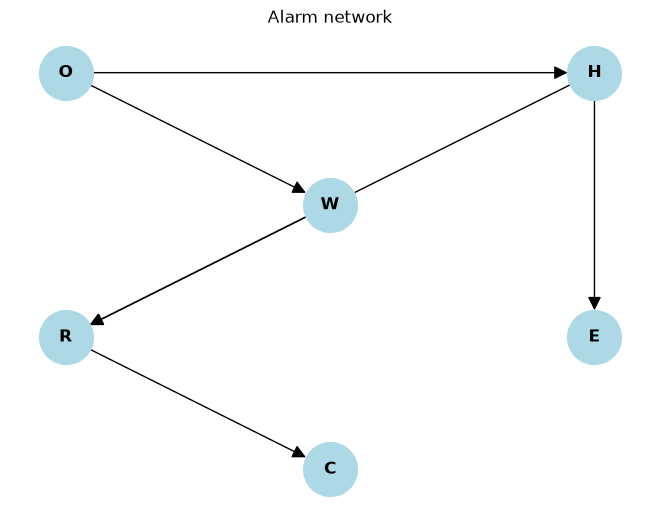

Model OK: True


In [9]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import networkx as nx
from pgmpy.models import DiscreteBayesianNetwork      # older pgmpy: BayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

# 1) Structure: list of (parent, child)
smartModel = DiscreteBayesianNetwork([("O","H"), ("O","W"), ("H","R"),
                                      ("W","R"), ("H","E"), ("R","C")])

# 2) CPDs. Rows = states of the child. Columns = parent combinations, LAST parent changes fastest.
cpd_o = TabularCPD("O", 2, [[0.3], 
                            [0.7]])
cpd_h = TabularCPD("H", 2, [[0.9,0.2],    #H=yes 
                            [0.1,0.8]], evidence=["O"],evidence_card=[2])   #H=no
cpd_w = TabularCPD("W", 2, [[0.1,0.6],    #H=yes 
                            [0.9,0.4]], evidence=["O"],evidence_card=[2])   #H=no 
cpd_r = TabularCPD("R", 2, [[0.6,0.9,0.3,0.5],    #H=warm 
                            [0.4,0.1,0.7,0.5]], evidence=["H","W"],evidence_card=[2,2])   #H=cold

cpd_e = TabularCPD("E", 2, [[0.8,0.2],    #E=h 
                            [0.2,0.8]], evidence=["H"],evidence_card=[2])   #H=low

cpd_c = TabularCPD("C", 2, [[0.85,0.4],    #E=h 
                            [0.15,0.6]], evidence=["R"],evidence_card=[2])   #H=low

smartModel.add_cpds(cpd_o,cpd_h,cpd_w,cpd_r,cpd_e,cpd_c)

pos = {"O": (-1, 2), "H": (1, 2), "W": (0, 1), "R": (-1, 0), "E": (1, 0), "C": (0,-1)}

G = nx.DiGraph(smartModel.edges())          # el grafo sale del modelo, así que siempre cuadra
nx.draw(G, pos, with_labels=True, node_size=1500, node_color="lightblue",
        arrowsize=20, font_weight="bold")
plt.title("Alarm network")
plt.savefig("alarm.png", dpi=150, bbox_inches="tight")
plt.show()

# 3) Consistency check (every column sums to 1, CPDs match the graph)
print("Model OK:", smartModel.check_model())

b) Perform inference using VariableElimination:
● Compute P(H = yes ∣ C = comfortable).
● Compute P(E = high ∣ C = comfortable).
● Find the MAP estimate (greatest probability) for (H,W ) given C = comfortable.

In [8]:
# Creamos el motor de inferencia
infer = VariableElimination(smartModel)

q1 = infer.query(variables=["H"], evidence={"C": 0})
print(q1)
#VARIABLE = LO QUE QUEREMOS SABER, EVIDENCE LO QUE SABEMOS
q2 = infer.query(variables=["E"], evidence={"C": 0,})
print(q2)

map_hw = infer.map_query(variables=["H", "W"], evidence={"C": 0})
print("MAP (H, W) | C = comfortable:", map_hw)
#Esto da la probabilidad
joint_hw = infer.query(variables=["H", "W"], evidence={"C": 0})
print(joint_hw)


+------+----------+
| H    |   phi(H) |
+======+==========+
| H(0) |   0.4823 |
+------+----------+
| H(1) |   0.5177 |
+------+----------+
+------+----------+
| E    |   phi(E) |
+======+==========+
| E(0) |   0.4894 |
+------+----------+
| E(1) |   0.5106 |
+------+----------+


Eliminating: O: 100%|██████████| 2/2 [00:00<00:00, 868.75it/s]

MAP (H, W) | C = comfortable: {'W': 1, 'H': 0}
+------+------+------------+
| H    | W    |   phi(H,W) |
+======+======+============+
| H(0) | W(0) |     0.1138 |
+------+------+------------+
| H(0) | W(1) |     0.3684 |
+------+------+------------+
| H(1) | W(0) |     0.2776 |
+------+------+------------+
| H(1) | W(1) |     0.2401 |
+------+------+------------+


In [11]:
print("W ⊥ E | H  ?", not smartModel.is_dconnected("W", "E", observed=["H"]))
print("O ⊥ C | R  ?", not smartModel.is_dconnected("O", "C", observed=["R"]))


W ⊥ E | H  ? True
O ⊥ C | R  ? True


**W ⊥ E | H → True.** There are two paths between W and E:
- W → R ← H → E: R is a collider and it is not observed, so the path is blocked (H is also observed).
- W ← O → H → E: O is a common cause and it is not observed, so it is open, but H is a chain node (O → H → E) and it is observed, so the path is blocked at H.
All paths are blocked, therefore W and E are independent given H.

**O ⊥ C | R → True.** There are two paths between O and C:
- O → H → R → C: R is a chain node and it is observed, so the path is blocked.
- O → W → R → C: R is again a chain node and it is observed, so the path is blocked.
All paths are blocked, therefore O and C are independent given R.

Subjetc 2 
a)


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from pathlib import Path
from hmmlearn import hmm  


pi = np.array([0.4,0.3,0.3]) #Walking, Running, Resting

#Matriz de transicion (como cambia de un dia a otro)
             # W    R   S
A = np.array([[0.6,0.3,0.1], #Desde Walking
                [0.2,0.7,0.1], # R
                [0.3,0.2,0.5]]) #Desde S

#Matriz de emision, (que ves en cada estado)
B  = np.array([[0.1, 0.7, 0.2],         # Walking: Low, Medium, High
               [0.05, 0.25, 0.7],
               [0.8, 0.15, 0.05]])        # Running: Normal, Fiebre
                                   

#3 hidden states
model = hmm.CategoricalHMM(n_components=3, init_params="", params="")   
model.n_features = 3                    # number of observation symbols
model.startprob_ = pi
model.transmat_ = A
model.emissionprob_ = B


b) Forward Algorithm: Compute the probability of observing the sequence:

Observations = [Medium, High, Low]

In [9]:

o = [1,2,0]
X = np.array(o).reshape(-1, 1)                       # hmmlearn wants a COLUMN of integers, shape (T, 1)
#Forward
log_p = model.score(X)
print("P(o) =", np.exp(log_p))


P(o) = 0.021117250000000008


**b) Forward algorithm.** We computed the probability of observing the sequence [Medium, High, Low] with the Forward algorithm (`model.score`, which returns the log-probability, so we apply `np.exp`).

**Result:** P(Medium, High, Low) ≈ 0.0211 (about 2.1 %).

**Interpretation:** this is the total probability of seeing these three sensor readings, summing over all possible sequences of hidden activities (3³ = 27 paths). The value is small because every extra observation multiplies by a probability lower than 1, so long sequences always have low probabilities. It does not tell us which activity the user was doing; that is answered by the Viterbi algorithm.

**b) Algoritmo Forward.** Hemos calculado la probabilidad de observar la secuencia [Medium, High, Low] con el algoritmo Forward (`model.score`, que devuelve el logaritmo de la probabilidad, por eso aplicamos `np.exp`).

**Resultado:** P(Medium, High, Low) ≈ 0,0211 (aproximadamente un 2,1 %).

**Interpretación:** es la probabilidad total de ver estas tres lecturas del sensor, sumando todas las posibles secuencias de actividades ocultas (3³ = 27 caminos). Sale pequeña porque cada observación nueva multiplica por una probabilidad menor que 1, así que las secuencias largas siempre tienen probabilidades bajas. No nos dice qué actividad hacía el usuario; eso lo responde el algoritmo de Viterbi.

c) Viterbi Algorithm: Find the most likely sequence of hidden states for the same observation

sequence. If the observation sequence were longer, why might the Viterbi algorithm be pre-
ferred over brute-force enumeration?

In [10]:
states = ["L","M","H"]
#Viterbi con libreria
log_p_best, path = model.decode(X, algorithm="viterbi")
print("hmmlearn Viterbi:", [states[s] for s in path], f" P = {np.exp(log_p_best):.4e}")


hmmlearn Viterbi: ['L', 'M', 'H']  P = 4.7040e-03


**c) Viterbi algorithm.** The most likely sequence of hidden states for [Medium, High, Low] is **Walking → Running → Resting**, with joint probability P(path, o) ≈ 0.0047. It matches intuition: medium readings fit walking, high readings fit running and low readings fit resting.

**Why Viterbi instead of brute force?** Brute force must evaluate every possible state sequence: with N states and T observations there are N^T paths (here 3³ = 27, but with T = 100 there are 3¹⁰⁰ ≈ 5·10⁴⁷), so the cost grows exponentially. Viterbi uses dynamic programming: at each time step it keeps only the best path ending in each state and reuses it in the next step, so the cost is O(T·N²), which grows linearly with the length of the sequence. It also gives exactly the same optimal path.

**c) Algoritmo de Viterbi.** La secuencia de estados ocultos más probable para [Medium, High, Low] es **Walking → Running → Resting**, con probabilidad conjunta P(camino, o) ≈ 0,0047. Tiene sentido: las lecturas medias encajan con caminar, las altas con correr y las bajas con descansar.

**¿Por qué Viterbi en vez de fuerza bruta?** La fuerza bruta tiene que evaluar todas las secuencias de estados posibles: con N estados y T observaciones hay N^T caminos (aquí 3³ = 27, pero con T = 100 serían 3¹⁰⁰ ≈ 5·10⁴⁷), así que el coste crece exponencialmente. Viterbi usa programación dinámica: en cada paso guarda solo el mejor camino que acaba en cada estado y lo reutiliza en el siguiente, así que el coste es O(T·N²), que crece de forma lineal con la longitud de la secuencia. Y da exactamente el mismo camino óptimo.

d) Generate 10,000 sequences using the HMM and estimate the empirical probability of the

observation sequence [M, H, L]. Compare with the exact probability from the Forward algo-
rithm.

Empirical P(M,H,L) = 0.0209  (209 of 10000 sequences)
Exact     P(M,H,L) = 0.0211  (Forward)
Absolute difference = 0.0002


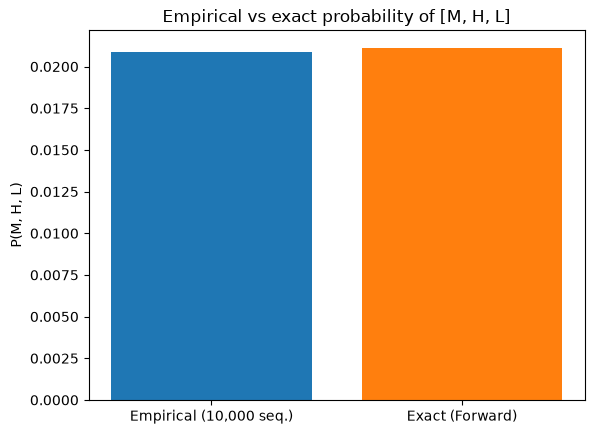

In [13]:
target = [1, 2, 0]                 # [Medium, High, Low]
n_seq = 10_000
T = len(target)                    # 3 observaciones por secuencia

hits = 0
for i in range(n_seq):
    X_s, Z_s = model.sample(T, random_state=i)   # una secuencia de 3 pasos
    if list(X_s.ravel()) == target:              # ¿ha salido M, H, L?
        hits += 1

p_empirical = hits / n_seq
p_exact = np.exp(model.score(np.array(target).reshape(-1, 1)))

print(f"Empirical P(M,H,L) = {p_empirical:.4f}  ({hits} of {n_seq} sequences)")
print(f"Exact     P(M,H,L) = {p_exact:.4f}  (Forward)")
print(f"Absolute difference = {abs(p_empirical - p_exact):.4f}")

# Gráfica: comparación de las dos probabilidades
plt.bar(["Empirical (10,000 seq.)", "Exact (Forward)"], [p_empirical, p_exact],
        color=["tab:blue", "tab:orange"])
plt.ylabel("P(M, H, L)")
plt.title("Empirical vs exact probability of [M, H, L]")
plt.savefig("hmm_empirical_vs_exact.png", dpi=150, bbox_inches="tight")
plt.show()